# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024160003          # <-- your full roll number
NAME = "Kushal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160003   Name: Kushal   Fingerprint: 708A59EF   Tickets: 15

Ticket_ID                                                                               Ticket_Text
      T01                               The projector is running slowly. Is there another solution?
      T02                                                 The printer won't print; it isn't jammed.
      T03                                       The lms keeps asking for login. Can you check this?
      T04              I couldn't connect to the e-mail since yesterday. I don't know what changed.
      T05                                                     I tried again... still no response!!!
      T06                                      The Matlab is showing an error. It worked yesterday.
      T07                                  Projector is showing an error on my laptop. Please help.
      T08                                                      Email me at helpdesk@university.edu.
      T09             

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [12]:
# Your code
import pandas as pd
from IPython.display import display

results = []
table_rows = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    unique_tokens = list(dict.fromkeys(result["tokens"]))

    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Tokens": result["tokens"],
        "Final Tokens": result["final"]
    })

    table_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(unique_tokens),
        "Final Tokens": len(result["final"])
    })

result_df = pd.DataFrame(table_rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(r["Sentences"] for r in table_rows),
    "Tokens": sum(r["Tokens"] for r in table_rows),
    "Punctuation Tokens": sum(r["Punctuation Tokens"] for r in table_rows),
    "Stopwords": sum(r["Stopwords"] for r in table_rows),
    "Unique Tokens": len(set(
        token for r in results for token in r["Tokens"]
    )),
    "Final Tokens": sum(r["Final Tokens"].__len__() for r in results)
}

result_df = pd.concat(
    [result_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(result_df)


selected_index = 0
selected_ticket = df.iloc[selected_index]
selected_result = process_ticket(selected_ticket["Ticket_Text"])

print("\nSelected Ticket:", selected_ticket["Ticket_ID"])
print("Original Text:", selected_ticket["Ticket_Text"])
print("Sentences:", selected_result["sentences"])
print("Tokens:", selected_result["tokens"])
print("Punctuation Tokens:", selected_result["punct"])
print("Stopwords:", selected_result["stops"])
print("Final Tokens:", selected_result["final"])

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,11,2,4,10,5
1,T02,1,11,2,3,10,6
2,T03,2,12,2,5,12,5
3,T04,2,17,2,6,14,9
4,T05,2,10,4,3,8,3
5,T06,2,11,2,4,10,5
6,T07,2,12,2,4,11,6
7,T08,1,7,2,2,7,3
8,T09,2,12,2,4,10,6
9,T10,2,15,2,6,13,7



Selected Ticket: T01
Original Text: The projector is running slowly. Is there another solution?
Sentences: ['The projector is running slowly.', 'Is there another solution?']
Tokens: ['the', 'projector', 'is', 'running', 'slowly', '.', 'is', 'there', 'another', 'solution', '?']
Punctuation Tokens: ['.', '?']
Stopwords: ['the', 'is', 'is', 'there']
Final Tokens: ['projector', 'running', 'slowly', 'another', 'solution']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

**Your answer:** The final tokens may include fragments such as n't and ca, which originate from contractions in the original ticket text. For example, the standard tokenizer can split can't into ca and n't. Since these fragments are neither punctuation-only tokens nor necessarily members of the stopword set, they can remain in the final tokens.
The exact fragments in your output depend on your generated tickets.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [15]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"\b\d+(?:[.,]\d+)*\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

email_pattern = r"\b[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"(?i)\b(?:https?://|www\.)[^\s<>]+"
phone_pattern = (
    r"(?<!\w)(?:\+\d{1,3}[- ]?)?"
    r"(?:\d{5}[- ]?\d{5}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)"
)

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print(f"\n{row['Ticket_ID']}: {text}")

    for label, pattern in patterns.items():
        print(f"{label}: {re.findall(pattern, text)}")

    cleaned = re.sub(email_pattern, "<EMAIL>", text)
    cleaned = re.sub(url_pattern, "<URL>", cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)

    print("Masked text:", cleaned)

print("\n--- TEST LINES ---")
for text in TEST_LINES:
    print("\nOriginal:", text)

    for label, pattern in patterns.items():
        print(f"{label}: {re.findall(pattern, text)}")

    cleaned = re.sub(email_pattern, "<EMAIL>", text)
    cleaned = re.sub(url_pattern, "<URL>", cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)

    print("Masked text:", cleaned)
sentence_initial_words = []

for text in df["Ticket_Text"]:
    for sentence in sent_tokenize(text):
        match = re.match(r"\s*([A-Z][a-zA-Z]*)\b", sentence)
        if match:
            sentence_initial_words.append(match.group(1))

print("Capitalized sentence-initial words:", len(sentence_initial_words))
print("Examples:", sentence_initial_words)


T01: The projector is running slowly. Is there another solution?
Words longer than 5 letters: ['projector', 'running', 'slowly', 'another', 'solution']
Numbers: []
Capitalized words: ['The', 'Is']
Words starting with a vowel: ['is', 'Is', 'another']
Masked text: The projector is running slowly. Is there another solution?

T02: The printer won't print; it isn't jammed.
Words longer than 5 letters: ['printer', 'jammed']
Numbers: []
Capitalized words: ['The']
Words starting with a vowel: ['it', 'isn']
Masked text: The printer won't print; it isn't jammed.

T03: The lms keeps asking for login. Can you check this?
Words longer than 5 letters: ['asking']
Numbers: []
Capitalized words: ['The', 'Can']
Words starting with a vowel: ['asking']
Masked text: The lms keeps asking for login. Can you check this?

T04: I couldn't connect to the e-mail since yesterday. I don't know what changed.
Words longer than 5 letters: ['couldn', 'connect', 'yesterday', 'changed']
Numbers: []
Capitalized words: ['

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 26

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [16]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

TOKEN_PATTERN = (
    r"(?i:https?://[^\s<>]+|www\.[^\s<>]+)|"
    r"[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"\+?\d{1,3}[- ]?\d{5}[- ]?\d{5}|"
    r"\d{4}[- ]\d{3}[- ]\d{4}|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:[-'][A-Za-z]+)*|"
    r"\d+|"
    r"[^\w\s]"
)

tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("--- TEST LINES ---")
for i, text in enumerate(TEST_LINES, start=1):
    print(f"\nTest line {i}: {text}")
    print("Custom tokenizer:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))

comparison_rows = []

for _, row in df.iterrows():
    custom_tokens = my_tokenize(row["Ticket_Text"])
    standard_tokens = word_tokenize(row["Ticket_Text"])

    comparison_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Custom Tokens": custom_tokens,
        "word_tokenize Tokens": standard_tokens,
        "Custom Count": len(custom_tokens),
        "word_tokenize Count": len(standard_tokens),
        "Different": custom_tokens != standard_tokens
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

different_tickets = comparison_df[comparison_df["Different"]]

print("Tickets tokenized differently:", len(different_tickets))
print("Ticket IDs:", different_tickets["Ticket_ID"].tolist())


--- TEST LINES ---

Test line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test line 3: The state-of-the-art lab i

,Ticket_ID,Custom Tokens,word_tokenize Tokens,Custom Count,word_tokenize Count,Different
0,T01,"[The, projector, is, running, slowly, ., Is, t...","[The, projector, is, running, slowly, ., Is, t...",11,11,False
1,T02,"[The, printer, won't, print, ;, it, isn't, jam...","[The, printer, wo, n't, print, ;, it, is, n't,...",9,11,True
2,T03,"[The, lms, keeps, asking, for, login, ., Can, ...","[The, lms, keeps, asking, for, login, ., Can, ...",12,12,False
3,T04,"[I, couldn't, connect, to, the, e-mail, since,...","[I, could, n't, connect, to, the, e-mail, sinc...",15,17,True
4,T05,"[I, tried, again, ., ., ., still, no, response...","[I, tried, again, ..., still, no, response, !,...",12,10,True
5,T06,"[The, Matlab, is, showing, an, error, ., It, w...","[The, Matlab, is, showing, an, error, ., It, w...",11,11,False
6,T07,"[Projector, is, showing, an, error, on, my, la...","[Projector, is, showing, an, error, on, my, la...",12,12,False
7,T08,"[Email, me, at, helpdesk@university.edu, .]","[Email, me, at, helpdesk, @, university.edu, .]",5,7,True
8,T09,"[VPN, is, showing, an, error, since, yesterday...","[VPN, is, showing, an, error, since, yesterday...",12,12,False
9,T10,"[Password, is, running, slowly, before, the, a...","[Password, is, running, slowly, before, the, a...",15,15,False


Tickets tokenized differently: 5
Ticket IDs: ['T02', 'T04', 'T05', 'T08', 'T12']


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 5 tickets.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [17]:
# Your code
from nltk.stem import (
    PorterStemmer, LancasterStemmer,
    RegexpStemmer, WordNetLemmatizer
)
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"ing$", min=5)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

unique_final_tokens = sorted(set(
    token
    for result in results
    for token in result["Final Tokens"]
))

tagged_words = dict(pos_tag(unique_final_tokens))
comparison_rows = []

for word in unique_final_tokens:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)

    tag = tagged_words[word]
    lemma_result = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    outputs = [
        porter_result, lancaster_result,
        regexp_result, lemma_result
    ]

    if len(set(outputs)) > 1:
        comparison_rows.append({
            "Original Word": word,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regexp_result,
            "WordNet Lemma": lemma_result
        })

stem_comparison_df = pd.DataFrame(comparison_rows)
display(stem_comparison_df)

print("Words supporting the 'ing' suffix rule:")
print([word for word in unique_final_tokens if word.endswith("ing")])

,Original Word,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,changed,chang,chang,changed,change
3,deadline,deadlin,deadlin,deadline,deadline
4,error,error,er,error,error
5,installed,instal,instal,installed,instal
6,jammed,jam,jam,jammed,jammed
7,keeps,keep,keep,keeps,keep
8,latest,latest,latest,latest,late
9,lms,lm,lms,lms,lm


Words supporting the 'ing' suffix rule:
['asking', 'restarting', 'running', 'showing', 'working']


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: error → er using the Regexp Stemmer.
Under-stemming: changed → chang using Porter Stemmer, while the WordNet lemma is change.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 (All Tokens),180,87,0.4833
1,S2 (No Punctuation),149,81,0.5436
2,S3 (Final Tokens),86,55,0.6395
3,S4 (Porter Stemmed),86,54,0.6279


Top 10 words of S1:
[('.', 22), ('the', 12), ('is', 11), ("n't", 6), ('i', 6), ('yesterday', 4), ('!', 4), ('showing', 4), ('an', 4), ('error', 4)]

Top 10 words of S3:
[("n't", 6), ('yesterday', 4), ('showing', 4), ('error', 4), ('password', 3), ('projector', 2), ('running', 2), ('slowly', 2), ('printer', 2), ('lms', 2)]


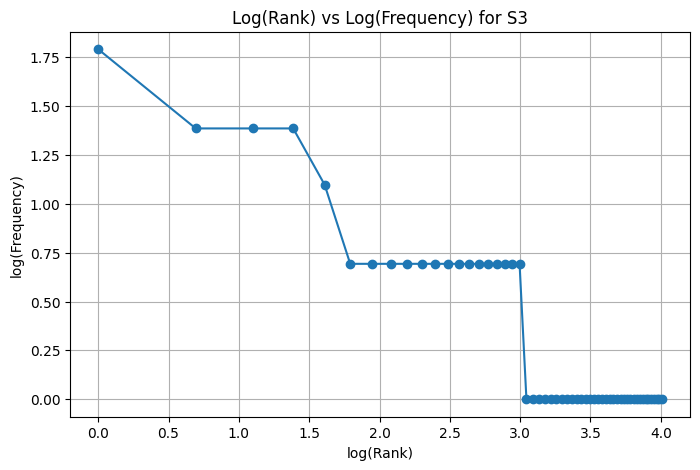


Top 5 bigrams of S1:
[(('.', 'i'), 5), (('yesterday', '.'), 4), (('is', 'showing'), 4), (('showing', 'an'), 4), (('an', 'error'), 4)]

Top 5 bigrams of S3:
[(('showing', 'error'), 4), (('running', 'slowly'), 2), (('keeps', 'asking'), 2), (('asking', 'login'), 2), (('since', 'yesterday'), 2)]


In [18]:
# Your code
from collections import Counter
from nltk.util import bigrams
import numpy as np
import matplotlib.pyplot as plt

S1 = [token for result in results for token in result["Tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in results for token in result["Final Tokens"]]
S4 = [porter.stem(token) for token in S3]

corpora = {
    "S1 (All Tokens)": S1,
    "S2 (No Punctuation)": S2,
    "S3 (Final Tokens)": S3,
    "S4 (Porter Stemmed)": S4
}

statistics = []

for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    statistics.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(statistics)
display(stats_df)

print("Top 10 words of S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

frequencies = Counter(S3).most_common()
ranks = np.arange(1, len(frequencies) + 1)
counts = np.array([frequency for word, frequency in frequencies])

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(counts), marker="o")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

print("\nTop 5 bigrams of S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams of S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

**Your answer:** TTR increases from 0.4833 in S1 to 0.6279 in S4 because punctuation removal, stop-word removal, and stemming reduce the total number of tokens while retaining many distinct words. In S1, punctuation and frequent words such as the and is lower the TTR. By S4, the corpus contains fewer tokens, and stemming combines some word variations, reducing unique tokens only slightly (from 87 to 54). Therefore, the proportion of unique tokens increases, resulting in a higher TTR.

In [19]:
#6. Interpretation Answer briefly:

#(a) Why does TTR change from S1 to S4 in your dataset?
#TTR increases from 0.4833 (S1) to 0.6279 (S4) as preprocessing reduces tokens more than unique words.

#(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
#word_tokenize() splits isn't into is and n't, while my_tokenize() keeps it as one token.

#(c) Give one example where stemming produces an undesirable result.
#Lancaster stemming changes error to er, an undesirable result.

#(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.
#WordNet lemmatization converts changed to change, while Porter stemming gives chang.